# Why a drone flies, advanced: power in forward flight, wind, air density and ground effect

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Why a drone flies](https://openskylab.space/edu_viz_why_drones_fly.html) · [česká verze](why_drones_fly_pro_cs.ipynb)

The advanced version of the drone flight notebook. According to the manufacturer the Mavic 3E hovers for 38 minutes but flies for 45 minutes at a constant 32.4 km/h, so it needs less power in forward flight than on the spot. You build a power model from momentum theory, calibrate it to these two figures and use it for the best speed for endurance and range, for the real wind at 120 m over the last three months, for air density and for flight close to the ground.

**Goal:** split drone power into induced, profile and parasite parts, calibrate the model to the manufacturer's figures, find the speed for maximum endurance and maximum range including headwind, evaluate the real wind and air density over 92 days, and estimate ground effect when hovering low.

**Data:** hourly wind at 10 and 120 m, temperature, humidity and pressure for the last 92 days from Open-Meteo for Roztoky (model data, not measurements); mass, propellers, battery and endurance of the Mavic 3E from the DJI data sheet (45 min of flight at a constant 32.4 km/h without wind at sea level until empty, 38 min of hover). The rotor figure of merit FM, the induced losses and the blade tip speed are estimates; the drive efficiency and drag area are calibrated by the notebook, so they also absorb all other losses (electronics, camera, battery).

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 55 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup

In [1]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

## 2. The power model and its calibration

We split power into three parts. **Induced** power accelerates air downwards; in forward flight more air passes through the disc, so a smaller induced velocity is enough (Glauert). **Profile** power is used by the drag of the propeller blades and grows slightly with speed. **Parasite** power overcomes the drag of the airframe and grows with the cube of speed. Two unknowns, the drive efficiency η and the equivalent drag area f, are set from the endurance in hover and in flight at 9 m/s.

In [2]:
g = 9.81
# Mavic 3E from the DJI data sheet: take-off mass, 9.4″ propellers, battery, endurance
m, n_rot, R, E_BAT = 0.915, 4, 9.4 * 0.0254 / 2, 77.0
T_HOVER, T_FLIGHT, V_TEST = 38, 45, 32.4 / 3.6     # min hover; min of flight at a constant 32.4 km/h; that speed in m/s
A = n_rot * np.pi * R ** 2                          # area of all discs
W = m * g
RHO0 = 1.225                                        # standard atmosphere density at sea level (kg/m³)
KAPPA = 1.15     # ◀ parameter: induced losses relative to an ideal disc (non-uniform inflow, tip losses)
FM = 0.60        # ◀ parameter: rotor efficiency in hover (figure of merit)
V_TIP = 90.0     # ◀ parameter: blade tip speed (m/s), an estimate
K_P = 4.65       # growth of profile power with forward speed (Leishman 2006)

def induced_velocity(T, V, alpha, rho):
    """Induced velocity in forward flight after Glauert (rotor tilted by alpha)."""
    vh = np.sqrt(T / (2 * rho * A))
    return brentq(lambda v: v - vh ** 2 / np.hypot(V * np.cos(alpha), V * np.sin(alpha) + v), 1e-6, 2 * vh)

def power(V, rho, fA, eta, mass=m):
    """Electrical power (W) in level flight at airspeed V: induced, profile, parasite."""
    Wt = mass * g
    D = 0.5 * rho * V ** 2 * fA                     # drag of the airframe
    T = np.hypot(Wt, D); alpha = np.arctan2(D, Wt)  # thrust and tilt
    Pi_h = Wt * np.sqrt(Wt / (2 * rho * A))         # ideal hover power
    Pi = KAPPA * T * induced_velocity(T, V, alpha, rho)
    P0 = (1 / FM - KAPPA) * Pi_h * (1 + K_P * (V / V_TIP) ** 2)
    Pp = D * V
    return np.array([Pi, P0, Pp]) / eta

# calibration to the manufacturer's figures: hover power sets the drive efficiency, power at 9 m/s the drag area
P_hover, P_test = E_BAT / (T_HOVER / 60), E_BAT / (T_FLIGHT / 60)
eta = W * np.sqrt(W / (2 * RHO0 * A)) / FM / P_hover
fA = brentq(lambda f: power(V_TEST, RHO0, f, eta).sum() - P_test, 1e-5, 0.5)
print(f"power from endurance: hover {P_hover:.1f} W, flight at {V_TEST:.0f} m/s {P_test:.1f} W")
print(f"calibration: drive and electronics efficiency η = {eta:.2f}, equivalent drag area f = Cd·S = {fA * 1e4:.0f} cm²")

power from endurance: hover 121.6 W, flight at 9 m/s 102.7 W
calibration: drive and electronics efficiency η = 0.56, equivalent drag area f = Cd·S = 282 cm²


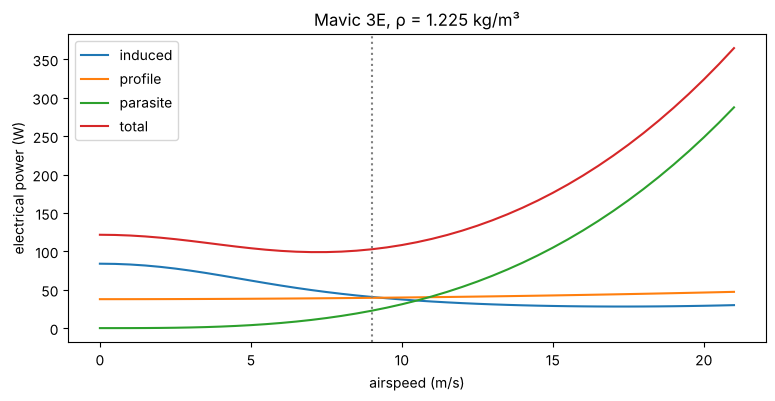

minimum power 99 W at 7.0 m/s → endurance 47 min
minimum energy per km 2.93 Wh/km at 11.5 m/s → range 26.3 km


,induced,profile,parasite,total
0.0,83.9,37.7,0.0,121.6
2.0,79.8,37.8,0.2,117.8
4.0,68.7,38.0,2.0,108.7
6.0,55.4,38.5,6.7,100.6
8.0,44.7,39.1,15.9,99.6
10.0,37.3,39.9,31.0,108.2
12.0,32.5,40.8,53.6,127.0
14.0,29.7,41.9,85.2,156.8
16.0,28.3,43.2,127.2,198.7
18.0,28.2,44.7,181.1,253.9


In [3]:
Vs = np.arange(0, 21.5, 0.5)
curve = pd.DataFrame([power(V, RHO0, fA, eta) for V in Vs], index=Vs, columns=["induced", "profile", "parasite"])
curve["total"] = curve.sum(axis=1)
V_end = curve["total"].idxmin()
V_rng = (curve["total"] / curve.index.to_series().replace(0, np.nan)).idxmin()
ax = curve.plot(figsize=(9, 4)); ax.axvline(V_TEST, color="gray", ls=":")
ax.set(xlabel="airspeed (m/s)", ylabel="electrical power (W)", title="Mavic 3E, ρ = 1.225 kg/m³"); plt.show()
print(f"minimum power {curve['total'].min():.0f} W at {V_end:.1f} m/s → endurance {E_BAT / curve['total'].min() * 60:.0f} min")
print(f"minimum energy per km {curve['total'][V_rng] / V_rng / 3.6:.2f} Wh/km at {V_rng:.1f} m/s → range {E_BAT / (curve['total'][V_rng] / V_rng / 3.6):.1f} km")
curve.iloc[::4].round(1)

> **✏️ Task 1.** Why does induced power decrease with speed and parasite power increase? At what speed does the drone have the longest endurance and at what speed the greatest range, and why are these not the same speed? Is the equivalent drag area f plausible for a drone the size of a Mavic (estimate the frontal area of the airframe and a drag coefficient of about 1)? Change `FM` to 0.5 and 0.7: how do the calibration and the resulting speeds change?

*Your answer:* 

## 3. Flying against the wind

With a headwind what counts is the energy per kilometre over the ground: power divided by the ground speed (V − wind). The table shows the best airspeed for different headwinds and a comparison with a constant 9 m/s.

In [4]:
rows = []
for wind in [0, 3, 6, 9, 12]:                      # wind against the flight direction (m/s)
    Vv = Vs[Vs > wind + 0.5]
    e = np.array([power(V, RHO0, fA, eta).sum() / (V - wind) / 3.6 for V in Vv])   # Wh per km over the ground
    k = e.argmin()
    rows.append({"headwind (m/s)": wind, "best airspeed (m/s)": Vv[k], "ground speed (m/s)": Vv[k] - wind,
                 "energy (Wh/km)": e[k], "at a constant 9 m/s (Wh/km)": power(9, RHO0, fA, eta).sum() / (9 - wind) / 3.6 if wind < 9 else np.inf})
pd.DataFrame(rows).set_index("headwind (m/s)").round(2)

,best airspeed (m/s),ground speed (m/s),energy (Wh/km),at a constant 9 m/s (Wh/km)
headwind (m/s),,,,
0,11.5,11.5,2.93,3.17
3,12.5,9.5,3.90,4.75
6,14.5,8.5,5.43,9.51
9,17.0,8.0,7.80,inf
12,20.5,8.5,11.23,inf


> **✏️ Task 2.** Why should the drone fly faster through the air in a headwind, although power increases? How many times more energy per kilometre does a return against a 6 m/s wind use at the optimum speed, and how many times at a constant 9 m/s? At what wind does the normal mode with 15 m/s stop being enough?

*Your answer:* 

## 4. Real wind over the last three months

From Open-Meteo we download the hourly wind at 10 and 120 m and the weather for 92 days for Roztoky and keep the daytime hours 8–18 h. For each hour we compute the energy per kilometre of a return if all of the wind at 120 m blew against it.

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


825 daytime hours with data in 92 days, wind at 120 m: median 4.0 m/s, 90th percentile 8.4 m/s
  wind at 120 m above  6.0 m/s: 29.7% of hours, at 10 m:  2.2%
  wind at 120 m above  9.0 m/s:  6.7% of hours, at 10 m:  0.0%
  wind at 120 m above 12.0 m/s:  0.6% of hours, at 10 m:  0.0%
energy per km of a return against the wind at 120 m: median 4.34 Wh/km, 90th percentile 7.22 Wh/km (no wind 2.93)


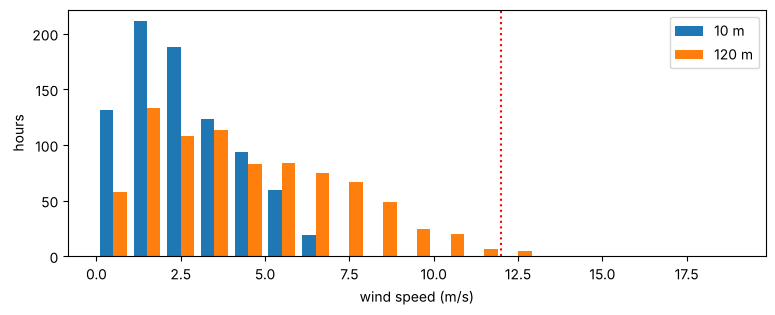

In [5]:
LAT, LON = 50.152, 14.392           # ◀ parameter: site (Roztoky)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms",
                "hourly": "wind_speed_10m,wind_speed_120m,temperature_2m,relative_humidity_2m,surface_pressure", "timezone": "Europe/Prague"})
met = pd.DataFrame(w["hourly"]).set_index("time"); met.index = pd.to_datetime(met.index)
day = met[(met.index.hour >= 8) & (met.index.hour <= 18)].dropna()   # only the hours when people usually fly
WIND_LIMIT = 12.0                   # ◀ parameter: wind resistance according to the manufacturer (m/s)
print(f"{len(day)} daytime hours with data in 92 days, wind at 120 m: median {day.wind_speed_120m.median():.1f} m/s, 90th percentile {day.wind_speed_120m.quantile(0.9):.1f} m/s")
for thr in [6, 9, WIND_LIMIT]:
    print(f"  wind at 120 m above {thr:4.1f} m/s: {np.mean(day.wind_speed_120m > thr):5.1%} of hours, at 10 m: {np.mean(day.wind_speed_10m > thr):5.1%}")
best = {wv: min(power(V, RHO0, fA, eta).sum() / (V - wv) / 3.6 for V in Vs[Vs > wv + 0.5]) for wv in np.arange(0, 16, 0.5)}
e_back = np.interp(day.wind_speed_120m, list(best), list(best.values()))
print(f"energy per km of a return against the wind at 120 m: median {np.median(e_back):.2f} Wh/km, 90th percentile {np.percentile(e_back, 90):.2f} Wh/km (no wind {best[0]:.2f})")
plt.figure(figsize=(9, 3.2)); plt.hist([day.wind_speed_10m, day.wind_speed_120m], bins=np.arange(0, 20, 1), label=["10 m", "120 m"])
plt.axvline(WIND_LIMIT, color="r", ls=":"); plt.xlabel("wind speed (m/s)"); plt.ylabel("hours"); plt.legend(); plt.show()

> **✏️ Task 3.** How does the wind at 10 m differ from the wind at 120 m, and what does that mean when you judge the wind on the ground before take-off? In what percentage of daytime hours would the wind at 120 m exceed the drone's wind resistance? How many per cent more energy per kilometre does a typical return against the wind use compared with calm air, and what follows for the battery reserve?

*Your answer:* 

## 5. Air density

From pressure, temperature and humidity we compute the air density at Roztoky over the same 92 days and add a density for high mountains. We assume that the rotor figure of merit FM and the drive efficiency η do not change with density.

In [6]:
met = met.dropna()
T = met.temperature_2m + 273.15
e_v = met.relative_humidity_2m / 100 * 6.112 * np.exp(17.62 * met.temperature_2m / (243.12 + met.temperature_2m))
rho = met.surface_pressure * 100 / (287.05 * T / (1 - 0.378 * e_v / met.surface_pressure))
RHO_MOUNTAIN = 0.90                 # ◀ parameter: density for high mountains (kg/m³), roughly 2600 m a.s.l.
cases = {"densest (Roztoky)": rho.max(), "thinnest (Roztoky)": rho.min(), "mountains": RHO_MOUNTAIN}
rows = {}
for name, r in cases.items():
    P = np.array([power(V, r, fA, eta).sum() for V in Vs])
    k_end, k_rng = P.argmin(), (P[1:] / Vs[1:]).argmin() + 1
    rows[name] = {"ρ (kg/m³)": r, "hover (W)": P[0], "hover (min)": E_BAT / P[0] * 60, "minimum power (W)": P[k_end],
                  "max-endurance speed (m/s)": Vs[k_end], "max-range speed (m/s)": Vs[k_rng], "range (km)": E_BAT / (P[k_rng] / Vs[k_rng] / 3.6)}
pd.DataFrame(rows).T.round(2)

,ρ (kg/m³),hover (W),hover (min),minimum power (W),max-endurance speed (m/s),max-range speed (m/s),range (km)
densest (Roztoky),1.27,119.43,38.68,97.16,7.0,11.0,26.29
thinnest (Roztoky),1.12,127.11,36.35,103.54,7.5,12.0,26.23
mountains,0.90,141.84,32.57,115.91,8.5,13.5,26.06


> **✏️ Task 4.** By how much does hover time shorten in thinner air, and how do the speeds for maximum endurance and maximum range shift? Why does the range in the mountains hardly change although power increases? (Compare how induced and parasite power depend on density.) What would happen if the drone carried a payload in the same mountains that increased its mass by 20 %? Try `m` in the model cell.

*Your answer:* 

## 6. Hovering close to the ground

Close to the ground the wake under the rotor cannot expand freely, the induced velocity drops and the same thrust needs less power. Cheeseman and Bennett (1955) described this as v_IGE / v_OGE = 1 − (R / 4z)², where z is the rotor height above the ground. The relation holds for a single rotor; with a quadcopter the wakes of the four propellers also interact.

In [7]:
def ground_factor(z):
    """Cheeseman and Bennett (1955): ratio of induced velocity near the ground to that out of ground effect at equal thrust."""
    return np.clip(1 - (R / (4 * z)) ** 2, 0, 1)

rows = []
Pi_h, P0_h, _ = power(0, RHO0, fA, eta)
for zR in [0.5, 0.75, 1, 1.5, 2, 3, 5]:          # rotor height above the ground in radii
    k = ground_factor(zR * R)
    P = Pi_h * k + P0_h
    rows.append({"z / R": zR, "z (cm)": zR * R * 100, "induced velocity (% of free air)": k * 100, "power (W)": P, "power saving (%)": (1 - P / (Pi_h + P0_h)) * 100})
pd.DataFrame(rows).set_index("z / R").round(1)

,z (cm),induced velocity (% of free air),power (W),power saving (%)
z / R,,,,
0.50,6.0,75.0,100.6,17.3
0.75,9.0,88.9,112.3,7.7
1.00,11.9,93.8,116.3,4.3
1.50,17.9,97.2,119.2,1.9
2.00,23.9,98.4,120.3,1.1
3.00,35.8,99.3,121.0,0.5
5.00,59.7,99.8,121.4,0.2


> **✏️ Task 5.** Up to what height above the ground is ground effect noticeable for the Mavic (power saving above 2 %)? Why does the drone "float" just above the ground when landing, and why is this more pronounced in metres for large propellers? Why does ground effect not help you over tall vegetation or over rippled water as much as over concrete?

*Your answer:* 

> **✏️ Extension (optional).** Adapt the model to the Matrice 350 RTK (mass 6.47 kg, 21″ propellers, battery 2 × 263 Wh). The manufacturer states 55 min of flight without payload; fill in `T_FLIGHT`, estimate `T_HOVER` and watch how endurance falls with payload up to the maximum take-off mass of 9.2 kg.

*Your answer:* 

---
### Data sources and references

- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI: *Mavic 3 Enterprise, specs* (https://enterprise.dji.com/mavic-3-enterprise/specs): take-off weight 915 g, 77 Wh battery, max. flight time 45 min and max. hover time 38 min without wind, wind resistance 12 m/s, max. speed 15 m/s in normal and 21 m/s in sport mode. The measurement conditions for 45 min (constant 32.4 km/h at sea level until empty) are given in resellers' data sheets.
- Leishman, J. G. (2006). *Principles of Helicopter Aerodynamics*, 2nd ed. Cambridge University Press (momentum theory in forward flight, power breakdown, K ≈ 4.65).
- Glauert, H. (1926). A general theory of the autogyro. *ARC R&M* 1111 (induced velocity in forward flight).
- Cheeseman, I. C., Bennett, W. E. (1955). The effect of the ground on a helicopter rotor in forward flight. *ARC R&M* 3021.
- Density of moist air via virtual temperature; saturation vapour pressure by the Magnus formula (WMO-No. 8, 2018).

### How to cite

OpenSkyLab (2026). Why a drone flies, advanced: power in forward flight, wind, air density and ground effect [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*